In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

from analysis import small_label_settings

In [2]:
experiment = 'full_pipeline'
file = f'../experiments/{experiment}/final_data.csv'

In [3]:
df = pd.read_csv(file)

# Remove controls
df = df[~df['fish'].str.contains('ctrl', case=False, na=False)]

In [4]:
# Group by barcode, fish, sample and aggregate
summary = (
    df.groupby(['barcode', 'fish', 'sample'])
      .agg(
          mean_proportion=('proportion', 'mean'),
          std_proportion=('proportion', 'std'),
          n_replicates=('replicate', 'count')
      )
      .reset_index()
)

In [5]:
N = 100

fake_df = []
for i in range(10):
    p = np.random.uniform()

    replicates = np.random.binomial(N, p, size = 3) / N

    d = {}
    d['mean_proportion'] = np.mean(replicates)
    d['std_proportion'] = np.std(replicates)
    d['n_replicates'] = 3

    fake_df.append(d)

fake_df = pd.DataFrame(fake_df)

In [6]:
def mle_N_from_proportions(df):
    # Filter out rows with only one replicate (no variance)
    df = df[df['n_replicates'] > 1].copy()

    p = df['mean_proportion'].values
    s2 = df['std_proportion'].values**2
    n = df['n_replicates'].values

    def neg_log_likelihood(N):
        if N <= 0:
            return np.inf
        var_model = p * (1 - p) / N
        return np.sum(n * (np.log(var_model) + s2 / var_model))

    result = minimize_scalar(neg_log_likelihood, bounds=(1e-3, 1e6), method='bounded')
    return result.x

# Example usage
N_mle = mle_N_from_proportions(summary[summary['std_proportion'] > 0])
print(f"Estimated shared Binomial M (MLE): {N_mle:.2f}")

Estimated shared Binomial M (MLE): 470.06


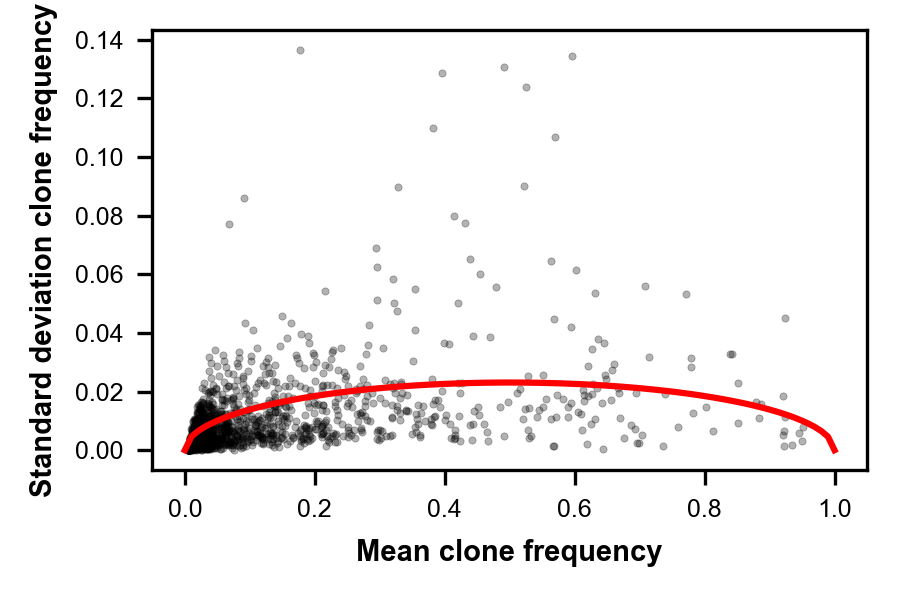

In [7]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, ax = plt.subplots(figsize = (3, 2), dpi = 300)
ax.scatter(
    summary['mean_proportion'],
    summary['std_proportion'],
    s=3,                 # point size
    linewidths=0.2,      # line width around markers
    edgecolors='black',
    # facecolors='#ffc566',
    facecolors='black',
    alpha=0.3
)

ps = np.linspace(0, 1, 100)
ax.plot(ps, np.sqrt((ps*(1-ps))/N_mle), color = 'red')

ax.set_xlabel('Mean clone frequency', fontweight = 'bold')
ax.set_ylabel('Standard deviation clone frequency', fontweight = 'bold')

plt.tight_layout()
plt.savefig('./images/model_fit/pseudosperm_fit.svg', bbox_inches = 'tight', pad_inches = 0)